In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RAW_DIR = Path("raw_data")

print("Current working directory:", Path.cwd())
print("Raw data folder exists:", RAW_DIR.exists())

required_files = [
    "waiting_times.csv",
    "link_attraction_park.csv",
    "glossary.xlsx",
    "entity_schedule.csv",
]

for filename in required_files:
    file_path = RAW_DIR / filename
    print(f"{filename}: {file_path.exists()}")

assert all((RAW_DIR / name).exists() for name in required_files), (
    "Required files were not found. "
    "Check that the notebook is running from theme-park-dashboard."
)

Current working directory: c:\Users\Calista\ml4biz\theme-park-dashboard
Raw data folder exists: True
waiting_times.csv: True
link_attraction_park.csv: True
glossary.xlsx: True
entity_schedule.csv: True


In [2]:
sample = pd.read_csv(
    RAW_DIR / "waiting_times.csv",
    nrows=1000,
)

print("Sample shape:", sample.shape)
display(sample.head())

sample.info()

display(
    sample.isna()
    .sum()
    .rename("missing_in_sample")
    .to_frame()
)

Sample shape: (1000, 14)


,WORK_DATE,DEB_TIME,DEB_TIME_HOUR,FIN_TIME,ENTITY_DESCRIPTION_SHORT,WAIT_TIME_MAX,NB_UNITS,GUEST_CARRIED,CAPACITY,ADJUST_CAPACITY,OPEN_TIME,UP_TIME,DOWNTIME,NB_MAX_UNIT
0,2018-01-01,2018-01-01 21:00:00.000,21,2018-01-01 21:15:00.000,Roller Coaster,0,2.0,0.0,0.000,0.00,0,0,0,2.0
1,2018-01-01,2018-01-01 19:30:00.000,19,2018-01-01 19:45:00.000,Bumper Cars,5,18.0,148.0,254.749,254.75,15,15,0,18.0
2,2018-01-01,2018-01-01 22:30:00.000,22,2018-01-01 22:45:00.000,Rapids Ride,0,1.0,0.0,0.000,0.00,0,0,0,2.0
3,2018-01-01,2018-01-01 12:45:00.000,12,2018-01-01 13:00:00.000,Crazy Dance,5,1.0,46.0,250.001,250.00,15,15,0,1.0
4,2018-01-01,2018-01-01 17:00:00.000,17,2018-01-01 17:15:00.000,Skyway,5,15.0,92.0,211.500,198.25,15,15,0,16.0


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   WORK_DATE                 1000 non-null   str    
 1   DEB_TIME                  1000 non-null   str    
 2   DEB_TIME_HOUR             1000 non-null   int64  
 3   FIN_TIME                  1000 non-null   str    
 4   ENTITY_DESCRIPTION_SHORT  1000 non-null   str    
 5   WAIT_TIME_MAX             1000 non-null   int64  
 6   NB_UNITS                  1000 non-null   float64
 7   GUEST_CARRIED             1000 non-null   float64
 8   CAPACITY                  1000 non-null   float64
 9   ADJUST_CAPACITY           1000 non-null   float64
 10  OPEN_TIME                 1000 non-null   int64  
 11  UP_TIME                   1000 non-null   int64  
 12  DOWNTIME                  1000 non-null   int64  
 13  NB_MAX_UNIT               1000 non-null   float64
dtypes: float64(5), int64

,missing_in_sample
WORK_DATE,0
DEB_TIME,0
DEB_TIME_HOUR,0
FIN_TIME,0
ENTITY_DESCRIPTION_SHORT,0
WAIT_TIME_MAX,0
NB_UNITS,0
GUEST_CARRIED,0
CAPACITY,0
ADJUST_CAPACITY,0


In [3]:
park_map = pd.read_csv(
    RAW_DIR / "link_attraction_park.csv",
    sep=";",
)

display(park_map.head())

print("Mapping columns:", park_map.columns.tolist())
print("Duplicate attraction names:",
      park_map["ATTRACTION"].duplicated().sum())

display(
    park_map.groupby("PARK")["ATTRACTION"]
    .nunique()
    .rename("attraction_count")
    .to_frame()
)

TARGET_PARK = "PortAventura World"

target_attractions = park_map.loc[
    park_map["PARK"].eq(TARGET_PARK),
    "ATTRACTION",
].tolist()

print("Selected park:", TARGET_PARK)
print("Number of attractions:", len(target_attractions))

,ATTRACTION,PARK
0,Aeroplane Ride,Tivoli Gardens
1,Bumper Cars,PortAventura World
2,Bungee Jump,PortAventura World
3,Circus Train,PortAventura World
4,Crazy Bus,Tivoli Gardens


Mapping columns: ['ATTRACTION', 'PARK']
Duplicate attraction names: 0


,attraction_count
PARK,
PortAventura World,26
Tivoli Gardens,13


Selected park: PortAventura World
Number of attractions: 26


In [4]:
columns_to_keep = [
    "WORK_DATE",
    "DEB_TIME",
    "FIN_TIME",
    "ENTITY_DESCRIPTION_SHORT",
    "WAIT_TIME_MAX",
    "OPEN_TIME",
    "UP_TIME",
    "DOWNTIME",
]

numeric_columns = [
    "WAIT_TIME_MAX",
    "OPEN_TIME",
    "UP_TIME",
    "DOWNTIME",
]

audit = {
    "all_raw_rows": 0,
    "target_park_rows": 0,
    "closed_rows": 0,
    "invalid_remaining_rows": 0,
    "retained_rows": 0,
}

raw_missing = pd.Series(0, index=sample.columns, dtype="int64")
clean_parts = []

reader = pd.read_csv(
    RAW_DIR / "waiting_times.csv",
    chunksize=200_000,
)

for chunk in reader:
    audit["all_raw_rows"] += len(chunk)
    raw_missing = raw_missing.add(chunk.isna().sum(), fill_value=0)

    # Select attractions belonging to the target park.
    selected = chunk.loc[
        chunk["ENTITY_DESCRIPTION_SHORT"].isin(target_attractions),
        columns_to_keep,
    ].copy()

    audit["target_park_rows"] += len(selected)

    for column in ["WORK_DATE", "DEB_TIME", "FIN_TIME"]:
        selected[column] = pd.to_datetime(
            selected[column], errors="coerce"
        )

    for column in numeric_columns:
        selected[column] = pd.to_numeric(
            selected[column], errors="coerce"
        )

    # Exclude records with zero opening time first.
    closed = selected["OPEN_TIME"].eq(0)
    audit["closed_rows"] += int(closed.sum())
    operating = selected.loc[~closed].copy()

    interval_minutes = (
        operating["FIN_TIME"] - operating["DEB_TIME"]
    ).dt.total_seconds() / 60

    valid = (
        operating[columns_to_keep].notna().all(axis=1)
        & operating["WAIT_TIME_MAX"].ge(0)
        & operating["OPEN_TIME"].gt(0)
        & operating["UP_TIME"].ge(0)
        & operating["DOWNTIME"].ge(0)
        & interval_minutes.gt(0)
        & operating["OPEN_TIME"].le(interval_minutes)
        & operating["UP_TIME"].le(operating["OPEN_TIME"])
        & operating["DOWNTIME"].le(operating["OPEN_TIME"])
        & (
            operating["OPEN_TIME"]
            - operating["UP_TIME"]
            - operating["DOWNTIME"]
        ).abs().le(0.001)
        & operating["WORK_DATE"].eq(
            operating["DEB_TIME"].dt.normalize()
        )
    )

    audit["invalid_remaining_rows"] += int((~valid).sum())
    audit["retained_rows"] += int(valid.sum())
    clean_parts.append(operating.loc[valid])

df = pd.concat(clean_parts, ignore_index=True)
del clean_parts

assert audit["target_park_rows"] == (
    audit["closed_rows"]
    + audit["invalid_remaining_rows"]
    + audit["retained_rows"]
)

display(pd.Series(audit, name="rows").to_frame())
display(raw_missing.astype("int64").rename("raw_missing").to_frame())

,rows
all_raw_rows,3509324
target_park_rows,2369821
closed_rows,1080609
invalid_remaining_rows,3
retained_rows,1289209


,raw_missing
WORK_DATE,0
DEB_TIME,0
DEB_TIME_HOUR,0
FIN_TIME,0
ENTITY_DESCRIPTION_SHORT,0
WAIT_TIME_MAX,0
NB_UNITS,0
GUEST_CARRIED,0
CAPACITY,0
ADJUST_CAPACITY,0


In [5]:
key_columns = [
    "WORK_DATE",
    "DEB_TIME",
    "FIN_TIME",
    "ENTITY_DESCRIPTION_SHORT",
]

summary = pd.Series({
    "selected_park": TARGET_PARK,
    "retained_rows": len(df),
    "attraction_count": df["ENTITY_DESCRIPTION_SHORT"].nunique(),
    "first_date": df["WORK_DATE"].min().date(),
    "last_date": df["WORK_DATE"].max().date(),
    "observed_dates": df["WORK_DATE"].nunique(),
    "duplicate_interval_keys": int(
        df.duplicated(subset=key_columns).sum()
    ),
    "zero_wait_records": int(df["WAIT_TIME_MAX"].eq(0).sum()),
})

display(summary.rename("result").to_frame())

display(
    df["WAIT_TIME_MAX"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .rename("wait_minutes")
    .to_frame()
)

interval_minutes = (
    df["FIN_TIME"] - df["DEB_TIME"]
).dt.total_seconds() / 60

display(
    interval_minutes.value_counts()
    .sort_index()
    .rename_axis("interval_minutes")
    .rename("record_count")
    .to_frame()
)

,result
selected_park,PortAventura World
retained_rows,1289209
attraction_count,26
first_date,2018-01-01
last_date,2022-08-18
observed_dates,1343
duplicate_interval_keys,0
zero_wait_records,41861


,wait_minutes
count,1.289209e+06
mean,2.301601e+01
std,2.210060e+01
min,0.000000e+00
25%,5.000000e+00
50%,1.500000e+01
75%,3.500000e+01
90%,5.000000e+01
95%,6.500000e+01
99%,9.000000e+01


,record_count
interval_minutes,
15.0,1289209


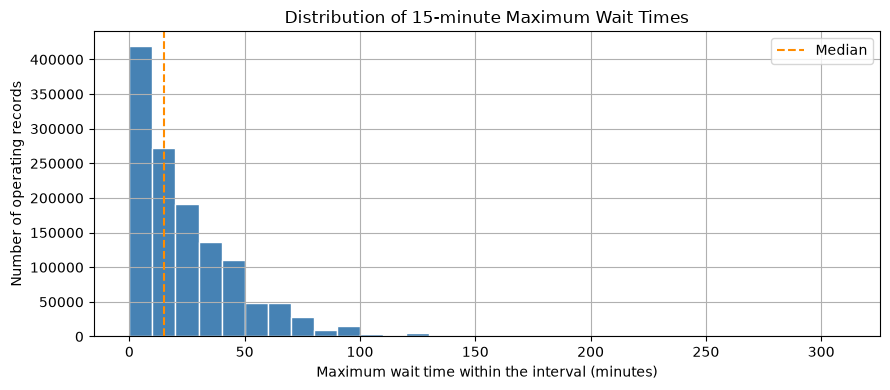

,threshold_minutes,records_above_threshold,share_above_threshold_pct
0,30,324943,25.20
1,45,159851,12.40
2,60,73200,5.68
3,90,12260,0.95


In [6]:
fig, ax = plt.subplots(figsize=(9, 4))

df["WAIT_TIME_MAX"].hist(
    bins=range(0, 311, 10),
    ax=ax,
    color="steelblue",
    edgecolor="white",
)

ax.axvline(
    df["WAIT_TIME_MAX"].median(),
    color="darkorange",
    linestyle="--",
    label="Median",
)

ax.set(
    title="Distribution of 15-minute Maximum Wait Times",
    xlabel="Maximum wait time within the interval (minutes)",
    ylabel="Number of operating records",
)
ax.legend()
plt.tight_layout()
plt.show()

threshold_comparison = pd.DataFrame({
    "threshold_minutes": [30, 45, 60, 90],
})

threshold_comparison["records_above_threshold"] = [
    int(df["WAIT_TIME_MAX"].gt(t).sum())
    for t in threshold_comparison["threshold_minutes"]
]

threshold_comparison["share_above_threshold_pct"] = (
    threshold_comparison["records_above_threshold"]
    / len(df) * 100
)

display(threshold_comparison.round(2))

In [7]:
yearly_coverage = (
    df.assign(year=df["WORK_DATE"].dt.year)
    .groupby("year")
    .agg(
        valid_records=("WAIT_TIME_MAX", "size"),
        observed_dates=("WORK_DATE", "nunique"),
        observed_attractions=("ENTITY_DESCRIPTION_SHORT", "nunique"),
        first_date=("WORK_DATE", "min"),
        last_date=("WORK_DATE", "max"),
        median_interval_max_wait=("WAIT_TIME_MAX", "median"),
    )
)

yearly_coverage["first_date"] = (
    yearly_coverage["first_date"].dt.date
)
yearly_coverage["last_date"] = (
    yearly_coverage["last_date"].dt.date
)

display(yearly_coverage)

,valid_records,observed_dates,observed_attractions,first_date,last_date,median_interval_max_wait
year,,,,,,
2018,348698,365,25,2018-01-01,2018-12-31,15.0
2019,355504,365,24,2019-01-01,2019-12-31,15.0
2020,174321,184,25,2020-01-01,2020-10-29,10.0
2021,192225,200,24,2021-06-15,2021-12-31,15.0
2022,218461,229,24,2022-01-01,2022-08-18,20.0


,valid_records,observed_dates,first_date,last_date,median_interval_max_wait,above_threshold_records,above_threshold_pct
ENTITY_DESCRIPTION_SHORT,,,,,,,
Spiral Slide,51919,1276,2018-01-01,2022-08-18,60.0,23116,44.52
Giant Wheel,64277,1323,2018-01-01,2022-08-18,45.0,15448,24.03
Free Fall,47800,1338,2018-01-01,2022-08-18,50.0,10746,22.48
Swing Ride,61491,1296,2018-01-01,2022-08-18,45.0,11059,17.98
Go-Karts,63175,1291,2018-01-01,2022-08-18,30.0,4716,7.46
Inverted Coaster,26818,848,2018-01-01,2022-08-18,25.0,1548,5.77
Spinning Coaster,65336,1343,2018-01-01,2022-08-18,25.0,2746,4.20
Bungee Jump,57605,1216,2018-01-01,2022-08-18,15.0,1533,2.66
Zipline,57215,1154,2018-01-01,2022-08-18,25.0,862,1.51


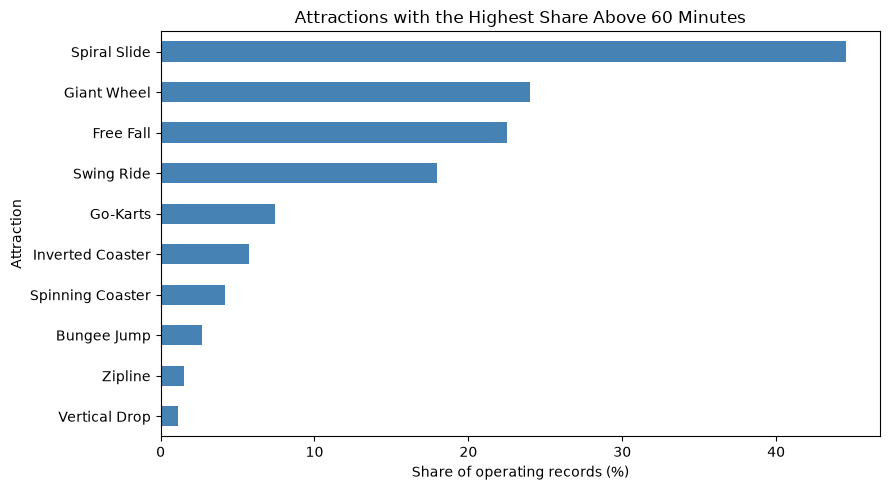

In [12]:
# Provisional business assumption, not an official service standard.
WAIT_THRESHOLD = 60

attraction_summary = (
    df.assign(
        above_threshold=df["WAIT_TIME_MAX"].gt(WAIT_THRESHOLD)
    )
    .groupby("ENTITY_DESCRIPTION_SHORT")
    .agg(
        valid_records=("WAIT_TIME_MAX", "size"),
        observed_dates=("WORK_DATE", "nunique"),
        first_date=("WORK_DATE", "min"),
        last_date=("WORK_DATE", "max"),
        median_interval_max_wait=("WAIT_TIME_MAX", "median"),
        above_threshold_records=("above_threshold", "sum"),
    )
)

attraction_summary["above_threshold_pct"] = (
    attraction_summary["above_threshold_records"]
    / attraction_summary["valid_records"] * 100
)

attraction_summary = attraction_summary.sort_values(
    "above_threshold_pct", ascending=False
)

display(
    attraction_summary.round({
        "median_interval_max_wait": 2,
        "above_threshold_pct": 2,
    })
)

top10 = attraction_summary.head(10).sort_values(
    "above_threshold_pct"
)

fig, ax = plt.subplots(figsize=(9, 5))

top10["above_threshold_pct"].plot.barh(
    ax=ax,
    color="steelblue",
)

ax.set(
    title=f"Attractions with the Highest Share Above {WAIT_THRESHOLD} Minutes",
    xlabel="Share of operating records (%)",
    ylabel="Attraction",
)

plt.tight_layout()
plt.show()

In [10]:
latest_date = df["WORK_DATE"].max().normalize()

# Exclude the calendar week containing the latest observation.
latest_week_start = latest_date - pd.Timedelta(
    days=latest_date.weekday()
)

PERIOD_END = latest_week_start - pd.Timedelta(days=1)
PERIOD_START = PERIOD_END - pd.Timedelta(days=55)

recent_df = df.loc[
    df["WORK_DATE"].between(PERIOD_START, PERIOD_END)
].copy()

recent_df["above_threshold"] = (
    recent_df["WAIT_TIME_MAX"].gt(WAIT_THRESHOLD)
)

print("Analysis window:",
      PERIOD_START.date(), "to", PERIOD_END.date())
print("Valid records:", len(recent_df))

recent_summary = (
    recent_df.groupby("ENTITY_DESCRIPTION_SHORT")
    .agg(
        valid_records=("WAIT_TIME_MAX", "size"),
        observed_dates=("WORK_DATE", "nunique"),
        median_interval_max_wait=("WAIT_TIME_MAX", "median"),
        above_threshold_records=("above_threshold", "sum"),
    )
)

recent_summary["above_threshold_pct"] = (
    recent_summary["above_threshold_records"]
    / recent_summary["valid_records"] * 100
)

# Provisional coverage rule for the classroom dashboard.
MIN_OBSERVED_DATES = 14

recent_summary["enough_observed_dates"] = (
    recent_summary["observed_dates"].ge(MIN_OBSERVED_DATES)
)

recent_summary = recent_summary.sort_values(
    "above_threshold_pct", ascending=False
)

display(recent_summary.round(2))

eligible_summary = recent_summary.loc[
    recent_summary["enough_observed_dates"]
]

assert not eligible_summary.empty, (
    "No attraction meets the provisional coverage rule."
)

SELECTED_ATTRACTION = eligible_summary.index[0]

print("Attraction selected for closer inspection:",
      SELECTED_ATTRACTION)

Analysis window: 2022-06-20 to 2022-08-14
Valid records: 58294


,valid_records,observed_dates,median_interval_max_wait,above_threshold_records,above_threshold_pct,enough_observed_dates
ENTITY_DESCRIPTION_SHORT,,,,,,
Spiral Slide,1799,55,90.0,1546,85.94,True
Free Fall,1837,55,60.0,799,43.49,True
Giant Wheel,3078,55,45.0,299,9.71,True
Swing Ride,2948,55,45.0,259,8.79,True
Zipline,3074,55,40.0,83,2.70,True
Roller Coaster,1617,55,40.0,38,2.35,True
Vertical Drop,1408,26,25.0,18,1.28,True
Inverted Coaster,1863,55,25.0,15,0.81,True
Go-Karts,3077,55,30.0,20,0.65,True


Attraction selected for closer inspection: Spiral Slide


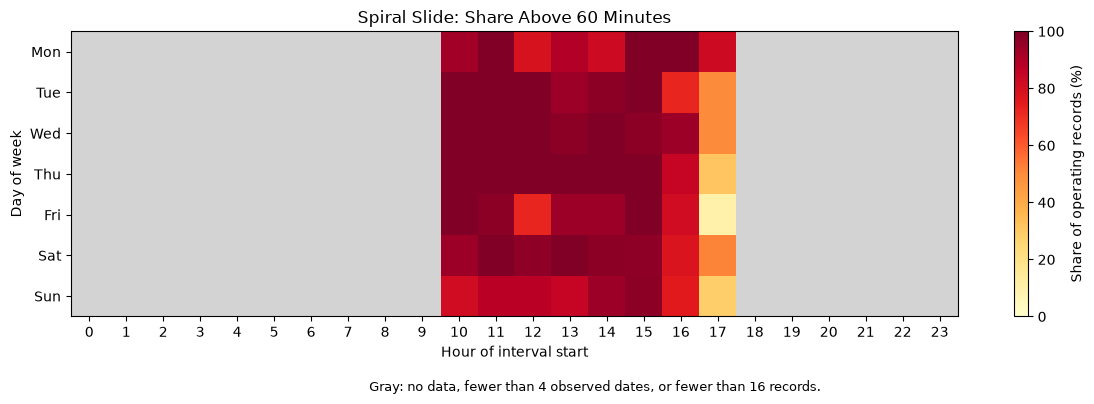

,weekday,hour,valid_records,observed_dates,above_threshold_records,above_threshold_pct,enough_coverage
2,0,11,28,7,28,100.0,True
6,0,15,28,7,28,100.0,True
7,0,16,28,7,28,100.0,True
25,2,14,32,8,32,100.0,True
16,1,15,32,8,32,100.0,True
13,1,12,32,8,32,100.0,True
12,1,11,32,8,32,100.0,True
11,1,10,32,8,32,100.0,True
22,2,11,32,8,32,100.0,True
23,2,12,32,8,32,100.0,True


In [11]:
selected_df = recent_df.loc[
    recent_df["ENTITY_DESCRIPTION_SHORT"].eq(
        SELECTED_ATTRACTION
    )
].copy()

selected_df["weekday"] = selected_df["WORK_DATE"].dt.weekday
selected_df["hour"] = selected_df["DEB_TIME"].dt.hour

slot_summary = (
    selected_df.groupby(["weekday", "hour"])
    .agg(
        valid_records=("WAIT_TIME_MAX", "size"),
        observed_dates=("WORK_DATE", "nunique"),
        above_threshold_records=("above_threshold", "sum"),
    )
    .reset_index()
)

slot_summary["above_threshold_pct"] = (
    slot_summary["above_threshold_records"]
    / slot_summary["valid_records"] * 100
)

# Mask cells with limited coverage.
slot_summary["enough_coverage"] = (
    slot_summary["observed_dates"].ge(4)
    & slot_summary["valid_records"].ge(16)
)

slot_summary["plot_pct"] = (
    slot_summary["above_threshold_pct"]
    .where(slot_summary["enough_coverage"])
)

heatmap = (
    slot_summary.pivot(
        index="weekday",
        columns="hour",
        values="plot_pct",
    )
    .reindex(index=range(7), columns=range(24))
)

cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad("lightgray")

fig, ax = plt.subplots(figsize=(12, 4))

im = ax.imshow(
    heatmap.to_numpy(),
    aspect="auto",
    cmap=cmap,
    vmin=0,
    vmax=100,
)

ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_yticks(range(7))
ax.set_yticklabels(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

ax.set(
    title=f"{SELECTED_ATTRACTION}: Share Above {WAIT_THRESHOLD} Minutes",
    xlabel="Hour of interval start",
    ylabel="Day of week",
)

fig.colorbar(im, ax=ax, label="Share of operating records (%)")
fig.text(
    0.5, 0.01,
    "Gray: no data, fewer than 4 observed dates, or fewer than 16 records.",
    ha="center",
    fontsize=9,
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

display(
    slot_summary.loc[slot_summary["enough_coverage"]]
    .sort_values("above_threshold_pct", ascending=False)
    .drop(columns="plot_pct")
    .head(10)
    .round(2)
)

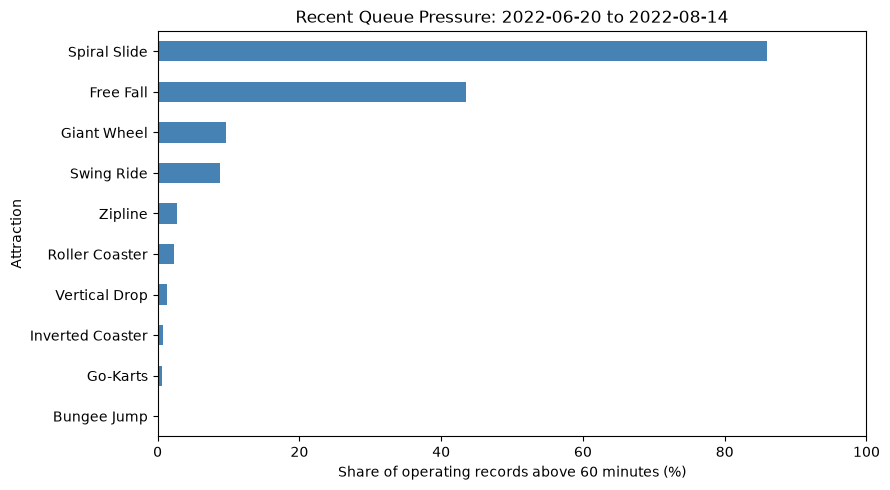

In [13]:
recent_top10 = (
    eligible_summary.head(10)
    .sort_values("above_threshold_pct")
)

fig, ax = plt.subplots(figsize=(9, 5))

recent_top10["above_threshold_pct"].plot.barh(
    ax=ax,
    color="steelblue",
)

ax.set(
    title=(
        f"Recent Queue Pressure: {PERIOD_START.date()} "
        f"to {PERIOD_END.date()}"
    ),
    xlabel=f"Share of operating records above {WAIT_THRESHOLD} minutes (%)",
    ylabel="Attraction",
    xlim=(0, 100),
)

plt.tight_layout()
plt.show()

In [14]:
app_data = (
    recent_df[
        [
            "WORK_DATE",
            "DEB_TIME",
            "ENTITY_DESCRIPTION_SHORT",
            "WAIT_TIME_MAX",
        ]
    ]
    .rename(columns={
        "WORK_DATE": "date",
        "DEB_TIME": "interval_start",
        "ENTITY_DESCRIPTION_SHORT": "attraction",
        "WAIT_TIME_MAX": "wait_minutes",
    })
    .sort_values(["date", "attraction", "interval_start"])
    .reset_index(drop=True)
)

assert not app_data.empty
assert app_data.notna().all().all()
assert app_data["wait_minutes"].ge(0).all()
assert not app_data.duplicated(
    subset=["attraction", "interval_start"]
).any()

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

OUTPUT_FILE = DATA_DIR / "park_queue_snapshot.csv"

app_data.to_csv(
    OUTPUT_FILE,
    index=False,
    date_format="%Y-%m-%d %H:%M:%S",
)

file_size_mb = OUTPUT_FILE.stat().st_size / 1_000_000

print("Saved to:", OUTPUT_FILE.resolve())
print("Rows:", len(app_data))
print("Attractions:", app_data["attraction"].nunique())
print("Date range:",
      app_data["date"].min().date(),
      "to", app_data["date"].max().date())
print(f"File size: {file_size_mb:.2f} MB")

assert file_size_mb < 25, "Further size reduction is required."

display(app_data.head())

Saved to: C:\Users\Calista\ml4biz\theme-park-dashboard\data\park_queue_snapshot.csv
Rows: 58294
Attractions: 23
Date range: 2022-06-21 to 2022-08-14
File size: 3.30 MB


,date,interval_start,attraction,wait_minutes
0,2022-06-21,2022-06-21 09:15:00,Bumper Cars,5
1,2022-06-21,2022-06-21 09:30:00,Bumper Cars,5
2,2022-06-21,2022-06-21 09:45:00,Bumper Cars,5
3,2022-06-21,2022-06-21 10:00:00,Bumper Cars,5
4,2022-06-21,2022-06-21 10:15:00,Bumper Cars,5
